In [1]:
# Purpose:
#   Quantify patient-level PBMC cell-type composition and test for compositional differences
#   across disease stages (within race) and across races (within stage), using ScanPro-derived
#   p-values, then visualize distributions as faceted boxplots with significance annotations.
#
# Summary:
#   - Load patient metadata (meta_pt.csv) and define ordered race-stage groups
#   - Load integrated single-cell AnnData (ft_all.h5ad) with final level-3 celltype labels
#   - Build a celltype × patient count matrix and convert to per-patient proportions
#   - Convert proportions to *within–major-lineage* ratios (B/T/DC/Mono/NK), then scale to %
#   - Merge ratios with patient metadata and save an analysis-ready CSV
#   - Create a multi-panel boxplot grid (one panel per level-3 cell type):
#       (1) disease state comparisons within each race (NHW: HRL/DCIS/BC; NHB: HRL/DCIS/BC)
#       (2) race comparisons within each stage (HRL/DCIS/BC: NHW vs NHB)
#   - Export publication-ready SVG figures and separate color legend SVGs

# Header

In [1]:
from utils import *
import math
from scanpro import scanpro

In [6]:
import scanpro
print(scanpro.__version__)

0.3.2


In [ ]:
sc.settings.set_figure_params(dpi=600, dpi_save=600)  # 600 dpi for publication
sc.settings.figdir = "plots/Figure1"

rcParams.update({
    'font.family': 'Arial',
    'svg.fonttype': 'none',    # Keep SVG text as font
    'font.size': 6,            # Main font size (5–7pt recommended)
    'axes.titlesize': 7,
    'axes.labelsize': 6,
    'xtick.labelsize': 5,
    'ytick.labelsize': 5,
    'legend.fontsize': 6,
    'legend.title_fontsize': 6,
    'figure.dpi': 600,

    # --- Nature Immunology-style axes/ticks ---
    'axes.linewidth': 0.5,          # Axis lines: 0.5 pt
    'xtick.major.width': 0.5,        # Major tick lines
    'ytick.major.width': 0.5,
    'xtick.minor.width': 0.5,
    'ytick.minor.width': 0.5,
    'lines.linewidth': 0.7,          # Plot/data lines
    'axes.grid': False,              # No grid lines

    # --- Ticks on all sides ---
    'xtick.direction': 'out',
    'ytick.direction': 'out',
    'xtick.top': False,
    'xtick.bottom': False,
    'ytick.left': True,
    'ytick.right': False,


    # --- Tick label padding (minimal) ---
    'xtick.major.pad': 0,
    'ytick.major.pad': 0,

    # ---- Thin lines for Nature Immunology style ----
    'lines.linewidth': 0.5,     # General line width (default: 1.5)
    'patch.linewidth': 0.5,     # Outline for violin/bars (default: 1.0)
    
})

# plt.rcParams['axes.grid'] = False      # Extra guarantee, if using seaborn
# sns.set_style("white")                 # Removes upper/right axes and grid

# -- Scanpy vector-friendly mode --
sc.settings._vector_friendly = True

In [8]:
os.chdir('../')

# Load data

In [10]:
meta = pd.read_csv('data/01_meta/meta_pt.csv')

print(len(meta['dataset_name'].unique()))

meta['race-stage'] = meta['race_stage'] #['race'].astype(str) + '-' + meta['group'].astype(str)
meta = meta.drop(columns=["race_stage"])

meta['race-stage'] = pd.Categorical(
    meta['race-stage'],
    categories=['NHW-HRL', 'NHW-DCIS', 'NHW-BC','NHB-HRL', 'NHB-DCIS', 'NHB-BC'],
    ordered=True
    )

meta

55


,sampleid,dataset_name,batch,viability_pct,group,race,age,diabetes,obesity,race-stage
0,9-D,Pool137_7,1,95,DCIS,NHW,37.0,N,Y,NHW-DCIS
1,30-D,Pool137_12,1,92,DCIS,NHW,78.0,N,N,NHW-DCIS
2,36-D,Pool137_18,1,93,DCIS,NHB,39.0,N,Y,NHB-DCIS
3,119-D,Pool137_20,1,95,DCIS,NHB,80.0,N,Y,NHB-DCIS
4,28-D,Pool137_24,1,94,DCIS,NHW,53.0,N,N,NHW-DCIS
5,53-D,Pool137_27,1,96,DCIS,NHB,45.0,N,N,NHB-DCIS
6,77-D,Pool137_30,1,90,DCIS,NHW,45.0,N,N,NHW-DCIS
7,31-D,Pool138_6,2,93,DCIS,NHW,44.0,N,N,NHW-DCIS
8,6-H,Pool137_6,1,94,HRL,NHW,71.1,N,Y,NHW-HRL
9,1-H,Pool137_10,1,88,HRL,NHW,62.3,N,N,NHW-HRL


In [11]:
dat = sc.read_h5ad(
    'data/03_cleandata/ft_all.h5ad'
)

dat.obs.columns

Index(['nFeaturess_RNA', 'nFeaturess_RNA_by_counts', 'total_counts',
       'total_counts_mt', 'pct_counts_mt', 'doublets_score', 'nCount_RNA',
       'nFeature_RNA', 'percent.mt', 'predicted.celltype.l1.score',
       'predicted.celltype.l1', 'predicted.celltype.l2.score',
       'predicted.celltype.l2', 'predicted.celltype.l3.score',
       'predicted.celltype.l3', 'mapping.score', 'RNA_snn_res.0.8',
       'seurat_clusters', 'dataset_name', 'RNA_snn_res.0.1', 'S.Score',
       'G2M.Score', 'Phase', 'celltype_level3'],
      dtype='object')

In [12]:
dat.obs = pd.merge(dat.obs, meta, 
                   on='dataset_name', how='left')

In [13]:
dat.obs.columns

Index(['nFeaturess_RNA', 'nFeaturess_RNA_by_counts', 'total_counts',
       'total_counts_mt', 'pct_counts_mt', 'doublets_score', 'nCount_RNA',
       'nFeature_RNA', 'percent.mt', 'predicted.celltype.l1.score',
       'predicted.celltype.l1', 'predicted.celltype.l2.score',
       'predicted.celltype.l2', 'predicted.celltype.l3.score',
       'predicted.celltype.l3', 'mapping.score', 'RNA_snn_res.0.8',
       'seurat_clusters', 'dataset_name', 'RNA_snn_res.0.1', 'S.Score',
       'G2M.Score', 'Phase', 'celltype_level3', 'sampleid', 'batch',
       'viability_pct', 'group', 'race', 'age', 'diabetes', 'obesity',
       'race-stage'],
      dtype='object')

In [14]:
with open('data/Legends/celltypelevel3_palette.pkl', 'rb') as f:
    
    celltype_palette = pkl.load(f)

    
celltype_palette

{'Naive B': (0.843137, 0.0, 0.0),
 'Mature B': (0.54902, 0.235294, 1.0),
 'Memory B': (0.007843, 0.533333, 0.0),
 'Plasmablast': (0.0, 0.67451, 0.780392),
 'Naive CD4T': (0.596078, 1.0, 0.0),
 'Central Memory CD4T': (1.0, 0.498039, 0.819608),
 'Effector Memory CD4T': (0.423529, 0.0, 0.309804),
 'Cytotoxic CD4T': (1.0, 0.647059, 0.188235),
 'Treg': (0.345098, 0.231373, 0.0),
 'Naive CD8T': (0.0, 0.341176, 0.34902),
 'Central Memory CD8T': (0.0, 0.0, 0.866667),
 'Effector Memory CD8T': (0.0, 0.992157, 0.811765),
 'Double Negative T': (0.631373, 0.458824, 0.415686),
 'γδ T': (0.737255, 0.717647, 1.0),
 'MAIT': (0.584314, 0.709804, 0.470588),
 'cDC1': (0.752941, 0.015686, 0.72549),
 'cDC2': (0.392157, 0.329412, 0.454902),
 'pDC': (0.47451, 0.0, 0.0),
 'Classical Monocyte': (0.027451, 0.454902, 0.847059),
 'Intermediate Monocyte': (0.996078, 0.960784, 0.564706),
 'Nonclassical Monocyte': (0.0, 0.294118, 0.0),
 'Cytotoxic Monocyte': (0.560784, 0.478431, 0.0),
 'CD56-dim NK': (1.0, 0.447059, 

In [15]:
meta_ordered = meta.sort_values([
    'race-stage','age'
]).set_index('dataset_name',drop=True)
    
pt_ordered = meta_ordered.index.tolist()


meta_ordered

,sampleid,batch,viability_pct,group,race,age,diabetes,obesity,race-stage
dataset_name,,,,,,,,,
Pool137_14,43-H,1,91,HRL,NHW,42.5,N,Y,NHW-HRL
Pool138_15,956-H,2,89,HRL,NHW,42.8,N,N,NHW-HRL
Pool138_14,568-H,2,93,HRL,NHW,43.7,N,N,NHW-HRL
Pool137_26,42-H,1,91,HRL,NHW,53.1,N,N,NHW-HRL
Pool138_9,63-H,2,98,HRL,NHW,57.7,N,Y,NHW-HRL
Pool137_25,36-H,1,90,HRL,NHW,59.6,N,N,NHW-HRL
Pool137_29,61-H,1,90,HRL,NHW,59.6,N,N,NHW-HRL
Pool138_4,24-H,2,94,HRL,NHW,60.5,N,Y,NHW-HRL
Pool137_10,1-H,1,88,HRL,NHW,62.3,N,N,NHW-HRL


In [16]:
ct = pd.crosstab(dat.obs['celltype_level3'], 
                   dat.obs['dataset_name'])
ct = ct.loc[:, pt_ordered]

pct = ct.div(ct.sum(axis=0))  #.sum(axis=0)

pct.index.name = None              # Remove the outer index name
pct.columns.name = None    

pct

,Pool137_14,Pool138_15,Pool138_14,Pool137_26,Pool138_9,Pool137_25,Pool137_29,Pool138_4,Pool137_10,Pool137_6,...,Pool138_19,Pool138_27,Pool137_31,Pool137_17,Pool137_16,Pool138_18,Pool138_29,Pool138_17,Pool138_20,Pool138_26
Naive B,0.070151,0.014172,0.078019,0.032960,0.053535,0.027157,0.063164,0.092120,0.018101,0.035602,...,0.037791,0.076304,0.141325,0.092935,0.058410,0.038982,0.167568,0.036818,0.020859,0.031377
Mature B,0.037312,0.043600,0.029102,0.047433,0.034138,0.101278,0.029163,0.013315,0.007835,0.035301,...,0.041969,0.024830,0.025737,0.071944,0.049793,0.059666,0.046708,0.018197,0.015644,0.023533
Memory B,0.011674,0.016339,0.016409,0.011409,0.017457,0.023802,0.014783,0.012681,0.003647,0.025988,...,0.054869,0.021769,0.012417,0.023303,0.030482,0.030231,0.009632,0.014177,0.005061,0.009413
Plasmablast,0.001418,0.000903,0.004747,0.000845,0.000485,0.001278,0.002553,0.001359,0.000810,0.001052,...,0.018714,0.004082,0.001129,0.003329,0.004309,0.001591,0.000000,0.001693,0.001687,0.001569
Naive CD4T,0.179577,0.161943,0.183695,0.145362,0.133450,0.111342,0.113291,0.197917,0.170066,0.103650,...,0.103743,0.065420,0.112428,0.069262,0.129907,0.180854,0.209658,0.139018,0.176687,0.066677
Central Memory CD4T,0.206306,0.159054,0.157688,0.165434,0.266996,0.175240,0.125521,0.238043,0.213292,0.167793,...,0.170967,0.252041,0.182978,0.204365,0.238270,0.194113,0.217971,0.378756,0.149693,0.161751
Cytotoxic CD4T,0.002182,0.002166,0.000929,0.001796,0.001455,0.003355,0.005913,0.001993,0.001621,0.001652,...,0.002544,0.000680,0.001129,0.001295,0.001915,0.004243,0.001451,0.005290,0.006442,0.000784
Effector Memory CD4T,0.028148,0.025636,0.025284,0.028417,0.051886,0.043131,0.013036,0.035417,0.021883,0.025387,...,0.031613,0.034467,0.022463,0.031441,0.020109,0.013789,0.021903,0.067076,0.015031,0.023376
Treg,0.024220,0.015075,0.014138,0.011832,0.018718,0.011342,0.006585,0.023732,0.011617,0.014271,...,0.014172,0.018707,0.012643,0.017662,0.023779,0.009281,0.026125,0.030047,0.026227,0.019925
Naive CD8T,0.072660,0.071222,0.071723,0.026410,0.016099,0.028115,0.058729,0.031069,0.034986,0.013820,...,0.096839,0.071882,0.095270,0.043277,0.040696,0.037125,0.017944,0.041684,0.008129,0.006903


In [17]:
pct.to_csv('data/Figure2/pct.csv')

# By race

Pct by major cell type

## Calc ratio

In [18]:
pct = pd.read_csv('data/Figure2/pct.csv', index_col=0)
pct

,Pool137_14,Pool138_15,Pool138_14,Pool137_26,Pool138_9,Pool137_25,Pool137_29,Pool138_4,Pool137_10,Pool137_6,...,Pool138_19,Pool138_27,Pool137_31,Pool137_17,Pool137_16,Pool138_18,Pool138_29,Pool138_17,Pool138_20,Pool138_26
Naive B,0.070151,0.014172,0.078019,0.032960,0.053535,0.027157,0.063164,0.092120,0.018101,0.035602,...,0.037791,0.076304,0.141325,0.092935,0.058410,0.038982,0.167568,0.036818,0.020859,0.031377
Mature B,0.037312,0.043600,0.029102,0.047433,0.034138,0.101278,0.029163,0.013315,0.007835,0.035301,...,0.041969,0.024830,0.025737,0.071944,0.049793,0.059666,0.046708,0.018197,0.015644,0.023533
Memory B,0.011674,0.016339,0.016409,0.011409,0.017457,0.023802,0.014783,0.012681,0.003647,0.025988,...,0.054869,0.021769,0.012417,0.023303,0.030482,0.030231,0.009632,0.014177,0.005061,0.009413
Plasmablast,0.001418,0.000903,0.004747,0.000845,0.000485,0.001278,0.002553,0.001359,0.000810,0.001052,...,0.018714,0.004082,0.001129,0.003329,0.004309,0.001591,0.000000,0.001693,0.001687,0.001569
Naive CD4T,0.179577,0.161943,0.183695,0.145362,0.133450,0.111342,0.113291,0.197917,0.170066,0.103650,...,0.103743,0.065420,0.112428,0.069262,0.129907,0.180854,0.209658,0.139018,0.176687,0.066677
Central Memory CD4T,0.206306,0.159054,0.157688,0.165434,0.266996,0.175240,0.125521,0.238043,0.213292,0.167793,...,0.170967,0.252041,0.182978,0.204365,0.238270,0.194113,0.217971,0.378756,0.149693,0.161751
Cytotoxic CD4T,0.002182,0.002166,0.000929,0.001796,0.001455,0.003355,0.005913,0.001993,0.001621,0.001652,...,0.002544,0.000680,0.001129,0.001295,0.001915,0.004243,0.001451,0.005290,0.006442,0.000784
Effector Memory CD4T,0.028148,0.025636,0.025284,0.028417,0.051886,0.043131,0.013036,0.035417,0.021883,0.025387,...,0.031613,0.034467,0.022463,0.031441,0.020109,0.013789,0.021903,0.067076,0.015031,0.023376
Treg,0.024220,0.015075,0.014138,0.011832,0.018718,0.011342,0.006585,0.023732,0.011617,0.014271,...,0.014172,0.018707,0.012643,0.017662,0.023779,0.009281,0.026125,0.030047,0.026227,0.019925
Naive CD8T,0.072660,0.071222,0.071723,0.026410,0.016099,0.028115,0.058729,0.031069,0.034986,0.013820,...,0.096839,0.071882,0.095270,0.043277,0.040696,0.037125,0.017944,0.041684,0.008129,0.006903


In [24]:
cells_ordered = [
    'Naive B','Mature B','Memory B','Plasmablast',
    'Naive CD4T','Central Memory CD4T','Effector Memory CD4T','Cytotoxic CD4T','Treg',
    'Naive CD8T','Central Memory CD8T','Effector Memory CD8T',
    'Double Negative T','γδ T','MAIT',
    'cDC1','cDC2','pDC',
    'Classical Monocyte','Intermediate Monocyte','Nonclassical Monocyte','Cytotoxic Monocyte',
    'CD56-dim NK','CD56-bright NK','Proliferating NK'
]


In [25]:
cells_group = {
    'B':[
 'Naive B',
 'Mature B',
 'Memory B',
 'Plasmablast'],
    
    'T':[
 'Naive CD4T',
 'Central Memory CD4T',
 'Effector Memory CD4T',
 'Cytotoxic CD4T',
 'Treg',
 'Naive CD8T',
 'Central Memory CD8T',
 'Effector Memory CD8T',
 'Double Negative T',
 'γδ T',
 'MAIT'],
    
    'DC':[
 'cDC1',
 'cDC2',
 'pDC'     
    ],
    
    'Mono':[
 'Classical Monocyte',
 'Intermediate Monocyte',
 'Nonclassical Monocyte',
 'Cytotoxic Monocyte'
        ],
    
    'NK':[
 'CD56-dim NK',
 'CD56-bright NK',
 'Proliferating NK'
    ]
}


In [21]:
new_pct = pd.DataFrame(index=pct.index, columns=pct.columns)

for group, cell_list in cells_group.items():
    # For each group, get the total per sample (across all group members)
    group_sum = pct.loc[cell_list].sum(axis=0)
    # Recalculate each member as a fraction of its group
    for cell in cell_list:
        new_pct.loc[cell] = pct.loc[cell] / group_sum

new_pct = new_pct.fillna(0) * 100
new_pct

,Pool137_14,Pool138_15,Pool138_14,Pool137_26,Pool138_9,Pool137_25,Pool137_29,Pool138_4,Pool137_10,Pool137_6,...,Pool138_19,Pool138_27,Pool137_31,Pool137_17,Pool137_16,Pool138_18,Pool138_29,Pool138_17,Pool138_20,Pool138_26
Naive B,58.190045,18.892900,60.820595,35.575827,50.688705,17.689906,57.598039,77.103867,59.555556,36.349693,...,24.644550,60.089286,78.250000,48.527282,40.848214,29.878049,74.837949,51.940299,48.226950,47.619048
Mature B,30.950226,58.122744,22.687047,51.197263,32.323232,65.972945,26.593137,11.144807,25.777778,36.042945,...,27.369668,19.553571,14.250000,37.566393,34.821429,45.731707,20.860342,25.671642,36.170213,35.714286
Memory B,9.683258,21.780987,12.791633,12.314709,16.528926,15.504683,13.480392,10.614102,12.000000,26.533742,...,35.781991,17.142857,6.875000,12.168035,21.316964,23.170732,4.301709,20.000000,11.702128,14.285714
Plasmablast,1.176471,1.203369,3.700724,0.912201,0.459137,0.832466,2.328431,1.137225,2.666667,1.073620,...,12.203791,3.214286,0.625000,1.738291,3.013393,1.219512,0.000000,2.388060,3.900709,2.380952
Naive CD4T,31.478294,31.011236,35.240546,31.237230,19.293326,27.913496,30.958502,33.834004,33.627137,19.508058,...,21.563444,14.222332,24.782284,16.353712,25.629723,34.707379,34.062165,17.335092,36.583042,19.495413
Central Memory CD4T,36.163702,30.458081,30.251435,35.550511,38.600673,43.932719,34.300404,40.693713,42.174145,31.580435,...,35.536254,54.794183,40.333416,48.253275,47.008816,37.251908,35.412647,47.229551,30.993966,47.293578
Cytotoxic CD4T,0.382482,0.414866,0.178183,0.385925,0.210320,0.841009,1.615865,0.340663,0.320513,0.310998,...,0.528701,0.147893,0.248818,0.305677,0.377834,0.814249,0.235798,0.659631,1.333757,0.229358
Effector Memory CD4T,4.934022,4.909248,4.850525,6.106697,7.501402,10.812976,3.562248,6.054506,4.326923,4.778061,...,6.570997,7.493222,4.951480,7.423581,3.967254,2.646310,3.558414,8.364116,3.112099,6.834862
Treg,4.245554,2.886776,2.712334,2.542565,2.706113,2.843412,1.799486,4.056984,2.297009,2.685892,...,2.945619,4.067045,2.786763,4.170306,4.691436,1.781170,4.244373,3.746702,5.430295,5.825688
Naive CD8T,12.736661,13.638721,13.759652,5.675369,2.327538,7.048458,16.048476,5.311242,6.917735,2.601074,...,20.128399,15.627311,21.000249,10.218341,8.028967,7.124682,2.915327,5.197889,1.683074,2.018349


## Calc FDR
Scanpro

In [53]:
# scanpro
level = 'celltype_level3'
var_cond = 'race'

idx = 0
for cell_major in ['B','T','DC','Mono','NK']:

    for group in ['HRL','DCIS','BC']:

        idx += 1

        sub = dat[(dat.obs['celltype_level3'].isin(cells_group[cell_major])) & 
             (dat.obs['group']==group)]
        
        out = scanpro(sub, 
              clusters_col=level, 
              conds_col=var_cond, 
              # covariates=vars_adj,
              samples_col='sampleid')

        res = out.results
             
        res['cell_major'] = cell_major
        res['group'] = group
        

        res_f = res if idx==1 else pd.concat((res_f, res))

res_f

[INFO] There are 2 conditions. T-Test will be performed...
[INFO] Done!
[INFO] There are 2 conditions. T-Test will be performed...
[INFO] Done!
[INFO] There are 2 conditions. T-Test will be performed...
[INFO] Done!
[INFO] There are 2 conditions. T-Test will be performed...
[INFO] Done!
[INFO] There are 2 conditions. T-Test will be performed...
[INFO] Done!
[INFO] There are 2 conditions. T-Test will be performed...
[INFO] Done!
[INFO] There are 2 conditions. T-Test will be performed...
[INFO] Done!
[INFO] There are 2 conditions. T-Test will be performed...
[INFO] Done!
[INFO] There are 2 conditions. T-Test will be performed...
[INFO] Done!
[INFO] There are 2 conditions. T-Test will be performed...
[INFO] Done!
[INFO] There are 2 conditions. T-Test will be performed...
[INFO] Done!
[INFO] There are 2 conditions. T-Test will be performed...
[INFO] Done!
[INFO] There are 2 conditions. T-Test will be performed...
[INFO] Done!
[INFO] There are 2 conditions. T-Test will be performed...
[INFO

,baseline_props,mean_props_NHW,mean_props_NHB,prop_ratio,t_statistics,p_values,adjusted_p_values,cell_major,group
clusters,,,,,,,,,
Naive B,0.503056,0.472465,0.528888,0.893318,-0.868247,0.391565,0.646654,B,HRL
Mature B,0.332323,0.360812,0.309734,1.164911,0.706294,0.484991,0.646654,B,HRL
Memory B,0.150881,0.151232,0.148552,1.018044,0.197117,0.844952,0.844952,B,HRL
Plasmablast,0.013739,0.015490,0.012826,1.207683,0.753472,0.456539,0.646654,B,HRL
Naive B,0.484876,0.532853,0.507948,1.049031,0.276329,0.787725,0.967624,B,DCIS
...,...,...,...,...,...,...,...,...,...
CD56-bright NK,0.064615,0.071150,0.068945,1.031974,-0.204303,0.842319,0.993689,NK,DCIS
Proliferating NK,0.013504,0.016626,0.015913,1.044825,1.092072,0.301056,0.903169,NK,DCIS
CD56-dim NK,0.926906,0.925392,0.891144,1.038432,1.485479,0.148522,0.222783,NK,BC


In [54]:
res_f[res_f['adjusted_p_values']<.1]

,baseline_props,mean_props_NHW,mean_props_NHB,prop_ratio,t_statistics,p_values,adjusted_p_values,cell_major,group
clusters,,,,,,,,,
Naive CD4T,0.254431,0.294102,0.223715,1.314629,2.664382,0.015099,0.083042,T,HRL
γδ T,0.000997,0.000590,0.001337,0.441105,-2.777425,0.011804,0.083042,T,HRL
Central Memory CD4T,0.346606,0.296580,0.407043,0.728621,-3.366054,0.002495,0.027446,T,BC
cDC1,0.037293,0.026560,0.053652,0.495044,-2.902781,0.004962,0.014886,DC,BC
Classical Monocyte,0.719192,0.766454,0.669302,1.145153,2.655913,0.014794,0.029587,Mono,HRL
Nonclassical Monocyte,0.194164,0.141658,0.251874,0.562418,-3.477225,0.002253,0.009014,Mono,HRL
Cytotoxic Monocyte,0.016964,0.022928,0.010552,2.172958,1.932154,0.066962,0.089283,Mono,HRL
Classical Monocyte,0.735972,0.761557,0.615860,1.236576,2.554362,0.025237,0.050474,Mono,DCIS
Nonclassical Monocyte,0.176728,0.152846,0.291688,0.524005,-2.624271,0.022186,0.050474,Mono,DCIS


In [19]:
res_f.to_csv('data/05_scanpro/byrace.csv')

In [14]:
res_f = pd.read_csv('data/05_scanpro/byrace.csv')
res_f

,clusters,baseline_props,mean_props_NHW,mean_props_NHB,prop_ratio,t_statistics,p_values,adjusted_p_values,cell_major,group
0,Naive B,0.503056,0.472465,0.528888,0.893318,-0.868247,0.391565,0.646654,B,HRL
1,Mature B,0.332323,0.360812,0.309734,1.164911,0.706294,0.484991,0.646654,B,HRL
2,Memory B,0.150881,0.151232,0.148552,1.018044,0.197117,0.844952,0.844952,B,HRL
3,Plasmablast,0.013739,0.015490,0.012826,1.207683,0.753472,0.456539,0.646654,B,HRL
4,Naive B,0.484876,0.532853,0.507948,1.049031,0.276329,0.787725,0.967624,B,DCIS
...,...,...,...,...,...,...,...,...,...,...
70,CD56-bright NK,0.064615,0.071150,0.068945,1.031974,-0.204303,0.842319,0.993689,NK,DCIS
71,Proliferating NK,0.013504,0.016626,0.015913,1.044825,1.092072,0.301056,0.903169,NK,DCIS
72,CD56-dim NK,0.926906,0.925392,0.891144,1.038432,1.485479,0.148522,0.222783,NK,BC
73,CD56-bright NK,0.059461,0.057157,0.089194,0.640820,-1.813656,0.080397,0.222783,NK,BC


## Export ST

In [13]:
res_f.columns

Index(['baseline_props', 'mean_props_NHW', 'mean_props_NHB', 'prop_ratio',
       't_statistics', 'p_values', 'adjusted_p_values', 'cell_major', 'group'],
      dtype='object')

In [17]:
dft = res_f[[
     'clusters','group',
    'mean_props_NHW', 'mean_props_NHB', 'prop_ratio',
        'p_values', 'adjusted_p_values'
]]
dft.columns = ['Cell type','Disease state',
               'Mean proportion in NHW', 'Mean proportion in NHB',
               'Proportion ratio NHW/NHB',
               'p-value', 'FDR-adjusted p-value'
              ]
dft

,Cell type,Disease state,Mean proportion in NHW,Mean proportion in NHB,Proportion ratio NHW/NHB,p-value,FDR-adjusted p-value
0,Naive B,HRL,0.472465,0.528888,0.893318,0.391565,0.646654
1,Mature B,HRL,0.360812,0.309734,1.164911,0.484991,0.646654
2,Memory B,HRL,0.151232,0.148552,1.018044,0.844952,0.844952
3,Plasmablast,HRL,0.015490,0.012826,1.207683,0.456539,0.646654
4,Naive B,DCIS,0.532853,0.507948,1.049031,0.787725,0.967624
...,...,...,...,...,...,...,...
70,CD56-bright NK,DCIS,0.071150,0.068945,1.031974,0.842319,0.993689
71,Proliferating NK,DCIS,0.016626,0.015913,1.044825,0.301056,0.903169
72,CD56-dim NK,BC,0.925392,0.891144,1.038432,0.148522,0.222783
73,CD56-bright NK,BC,0.057157,0.089194,0.640820,0.080397,0.222783


In [18]:
dft.to_csv('data/Tables/!ST2_propByrace.csv', index=False)

## Plot

In [45]:
dfp = pd.read_csv('data/Figure2/ratio_majorCellTypes.csv', index_col=0)
dfp

,dataset_name,Naive B,Mature B,Memory B,Plasmablast,Naive CD4T,Central Memory CD4T,Effector Memory CD4T,Cytotoxic CD4T,Treg,...,CD56-bright NK,Proliferating NK,batch,viability_pct,group,race,age,diabetes,obesity,race-stage
0,Pool137_14,58.190045,30.950226,9.683258,1.176471,31.478294,36.163702,4.934022,0.382482,4.245554,...,7.512953,1.208981,1,91,HRL,NHW,42.5,N,Y,NHW-HRL
1,Pool138_15,18.892900,58.122744,21.780987,1.203369,31.011236,30.458081,4.909248,0.414866,2.886776,...,15.130435,1.391304,2,89,HRL,NHW,42.8,N,N,NHW-HRL
2,Pool138_14,60.820595,22.687047,12.791633,3.700724,35.240546,30.251435,4.850525,0.178183,2.712334,...,9.687034,2.384501,2,93,HRL,NHW,43.7,N,N,NHW-HRL
3,Pool137_26,35.575827,51.197263,12.314709,0.912201,31.237230,35.550511,6.106697,0.385925,2.542565,...,11.111111,0.750751,1,91,HRL,NHW,53.1,N,N,NHW-HRL
4,Pool138_9,50.688705,32.323232,16.528926,0.459137,19.293326,38.600673,7.501402,0.210320,2.706113,...,4.545455,1.704545,2,98,HRL,NHW,57.7,N,Y,NHW-HRL
5,Pool137_25,17.689906,65.972945,15.504683,0.832466,27.913496,43.932719,10.812976,0.841009,2.843412,...,14.356436,4.455446,1,90,HRL,NHW,59.6,N,N,NHW-HRL
6,Pool137_29,57.598039,26.593137,13.480392,2.328431,30.958502,34.300404,3.562248,1.615865,1.799486,...,7.022472,1.966292,1,90,HRL,NHW,59.6,N,N,NHW-HRL
7,Pool138_4,77.103867,11.144807,10.614102,1.137225,33.834004,40.693713,6.054506,0.340663,4.056984,...,10.821382,1.173403,2,94,HRL,NHW,60.5,N,Y,NHW-HRL
8,Pool137_10,59.555556,25.777778,12.000000,2.666667,33.627137,42.174145,4.326923,0.320513,2.297009,...,4.077670,2.135922,1,88,HRL,NHW,62.3,N,N,NHW-HRL
9,Pool137_6,36.349693,36.042945,26.533742,1.073620,19.508058,31.580435,4.778061,0.310998,2.685892,...,6.934307,2.189781,1,94,HRL,NHW,71.1,N,Y,NHW-HRL


In [46]:
from statannotations.Annotator import Annotator
from scipy.stats import f_oneway

dfp['race-stage'] = pd.Categorical(
    dfp['race-stage'],
    categories=['NHW-HRL','NHB-HRL',  'NHW-DCIS','NHB-DCIS',  'NHW-BC','NHB-BC'],
    ordered=True
    )

color_set = {
    'NHW-HRL':'#3194CC',
    'NHW-DCIS':'#825CA6',
    'NHW-BC':'#06948E',
    
    'NHB-HRL':'#F2B342',
    'NHB-DCIS':'#F472B6',
    'NHB-BC':'#C03830'

# 'Diabetes':'#F472B6',
# 'Obesity':'#F59E42'

}

major_celltype_palette = {
    'B':    '#3072C4',   # strong blue
    'T':    '#EF763F',   # bold orange
    'DC':   '#35A293',   # teal
    'Mono': '#B3813E',   # rich brown/gold
    'NK':   '#7D4C99',   # deep purple
}

cells_group = {
    'B':['Naive B',
 'Mature B',
 'Memory B',
 'Plasmablast'],
    'T':['Naive CD4T',
 'Central Memory CD4T',
 'Effector Memory CD4T',
 'Cytotoxic CD4T',
 'Treg',
 'Naive CD8T',
 'Central Memory CD8T',
 'Effector Memory CD8T',
 'Double Negative T',
 'γδ T',
 'MAIT'],
    'DC':[
   'cDC1',
 'cDC2',
 'pDC'     
    ],
    'Mono':[
        'Classical Monocyte',
 'Intermediate Monocyte',
 'Nonclassical Monocyte',
 'Cytotoxic Monocyte'
        ],
    'NK':[
        'CD56-dim NK',
 'CD56-bright NK',
 'Proliferating NK'
    ]
}



# Define the group for each pair (extract the trailing substring after '-' from NHW-HRL, etc.)
def get_group(pair):
    # E.g., ('NHW-HRL', 'NHB-HRL') -> 'HRL'
    return pair[0].split('-')[1]

def pval_to_star(p):
    # Customize as you wish (this is standard)
    if p < 0.001:
        return '***'
    elif p < 0.01:
        return '**'
    elif p < 0.05:
        return '*'
    else:
        return 'ns'

def get_group_from_celltype(celltype, cells_group):
    for group, members in cells_group.items():
        if celltype == members or celltype in members:
            return group
    return None

In [47]:
res_f = pd.read_csv('data/05_scanpro/byrace.csv', index_col=0
                   )
res_f

,baseline_props,mean_props_NHW,mean_props_NHB,prop_ratio,t_statistics,p_values,adjusted_p_values,cell_major,group
clusters,,,,,,,,,
Naive B,0.503056,0.472465,0.528888,0.893318,-0.868247,0.391565,0.646654,B,HRL
Mature B,0.332323,0.360812,0.309734,1.164911,0.706294,0.484991,0.646654,B,HRL
Memory B,0.150881,0.151232,0.148552,1.018044,0.197117,0.844952,0.844952,B,HRL
Plasmablast,0.013739,0.015490,0.012826,1.207683,0.753472,0.456539,0.646654,B,HRL
Naive B,0.484876,0.532853,0.507948,1.049031,0.276329,0.787725,0.967624,B,DCIS
...,...,...,...,...,...,...,...,...,...
CD56-bright NK,0.064615,0.071150,0.068945,1.031974,-0.204303,0.842319,0.993689,NK,DCIS
Proliferating NK,0.013504,0.016626,0.015913,1.044825,1.092072,0.301056,0.903169,NK,DCIS
CD56-dim NK,0.926906,0.925392,0.891144,1.038432,1.485479,0.148522,0.222783,NK,BC


In [51]:
# significant

cells_plot = [x for x in cells_ordered if x in res_f[res_f['adjusted_p_values']<.05].index.unique()]
cells_plot

['Central Memory CD4T', 'cDC1', 'Classical Monocyte', 'Nonclassical Monocyte']

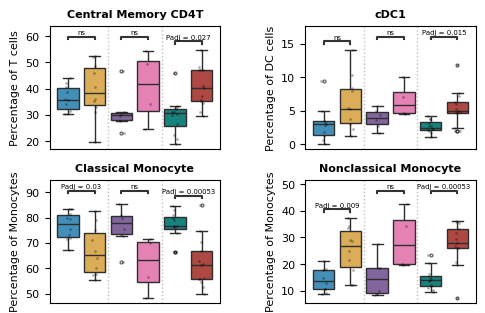

In [52]:
# Plot significant
ncol = 2
features =  cells_plot  # the cell type names
nrow = int(np.ceil(len(features)/ncol))
figwidth = 5.5
figheight = nrow * 1.8 # or adjust as needed

fig, axs = plt.subplots(nrow, ncol, figsize=(figwidth, figheight), sharex=True, gridspec_kw={"hspace": 0.25, "wspace": 0.5})

axs = axs.flatten()

for i, yname in enumerate(features):
    ax = axs[i]
    sns.boxplot(
        data=dfp,
        x='race-stage',
        y=yname,
        hue='race-stage',
        palette=color_set,
        flierprops=dict(marker='o', markersize=2, alpha=0.7),
        ax=ax,
        showfliers=True
    )
    sns.stripplot(
        data=dfp, x='race-stage', y=yname, size=2, color='black', alpha=.3, ax=ax
    )


    n_cat = dfp['race-stage'].nunique()
    
    # boundaries for 2+2+2 split
    split_positions = [n_cat/3 - 0.5, 2*n_cat/3 - 0.5]  # 6 → [1.5, 3.5]
    
    for x in split_positions:
        ax.axvline(
            x=x,
            linestyle=':',
            color='gray',
            alpha=0.5,
            linewidth=1
        )
    
    pairs = [
        ('NHW-HRL', 'NHB-HRL'),
        ('NHW-DCIS', 'NHB-DCIS'),
        ('NHW-BC', 'NHB-BC')
    ]
    
    # --- Prepare custom pvalues (and stars) ---
    custom_annotations = []
    
    for pair in pairs:
        group = get_group(pair)
    
        try:
            padj = (
                res_f.loc[yname]
                .query("group == @group")["adjusted_p_values"]   # your adjusted p-values
                .iloc[0]
            )
            padj = float(padj)
    
            if padj > 0.05:
                label = "ns"
            else:
                label = f"Padj = {padj:.2g}"
    
        except Exception as e:
            print(f"Missing adjusted p-value for {yname}, {group}: {e}")
            label = "Padj = NA"
    
        custom_annotations.append(label)
    
    
    annotator = Annotator(
        ax,
        pairs,
        data=dfp,
        x="race-stage",
        y=yname,
    )
    
    annotator.configure(
        loc="inside",
        verbose=False,
        fontsize=5
    )

    annotator.set_custom_annotations(custom_annotations)
    annotator.annotate()


    groupname = get_group_from_celltype(yname, cells_group)
    groupname = f'{groupname} cells' if groupname!='Mono' else 'Monocytes'
    title_color = major_celltype_palette.get(groupname, 'black')


    ax.set_title(yname, fontsize=8, color='k', fontweight='bold')
    ax.set_xlabel('')
    ax.set_ylabel(f'Percentage of {groupname}', fontsize=8)  # Hide to save space
    ax.tick_params(axis='x', labelsize=8, rotation=90, length=0
                  )
    ax.tick_params(axis='y', labelsize=8)
    ax.legend([],[], frameon=False)  # Remove legend
    ax.set_xticklabels('')

    # for tick_label in ax.get_xticklabels():
    #     group = tick_label.get_text()
    #     if group in color_set:
    #         tick_label.set_color(color_set[group])

    

# Hide any unused subplots
for j in range(i+1, len(axs)):
    axs[j].set_visible(False)

group_palette = {
    'HRL': '#F5C16C',   # light gold
    'DCIS': '#EA7D30',  # orange
    'BC': '#7A491A',    # deep brown (darkest)
}

# Mapping from tick positions (0-based index) to group labels
tick_groups = {
    (0, 1): 'HRL',
    (2, 3): 'DCIS',
    (4, 5): 'BC'
}



# Shared axis label
fig.text(0.5, 0.04, '', ha='center', fontsize=7)
# fig.text(0.03, 0.5, 'Cell Percentage', va='center', rotation='vertical', fontsize=7)

plt.tight_layout(rect=[0.04, 0.04, 1, 1])  # leave space for axis labels
plt.savefig('plots/F2/RE_byrace.svg', bbox_inches='tight', dpi=600)

In [ ]:
# others


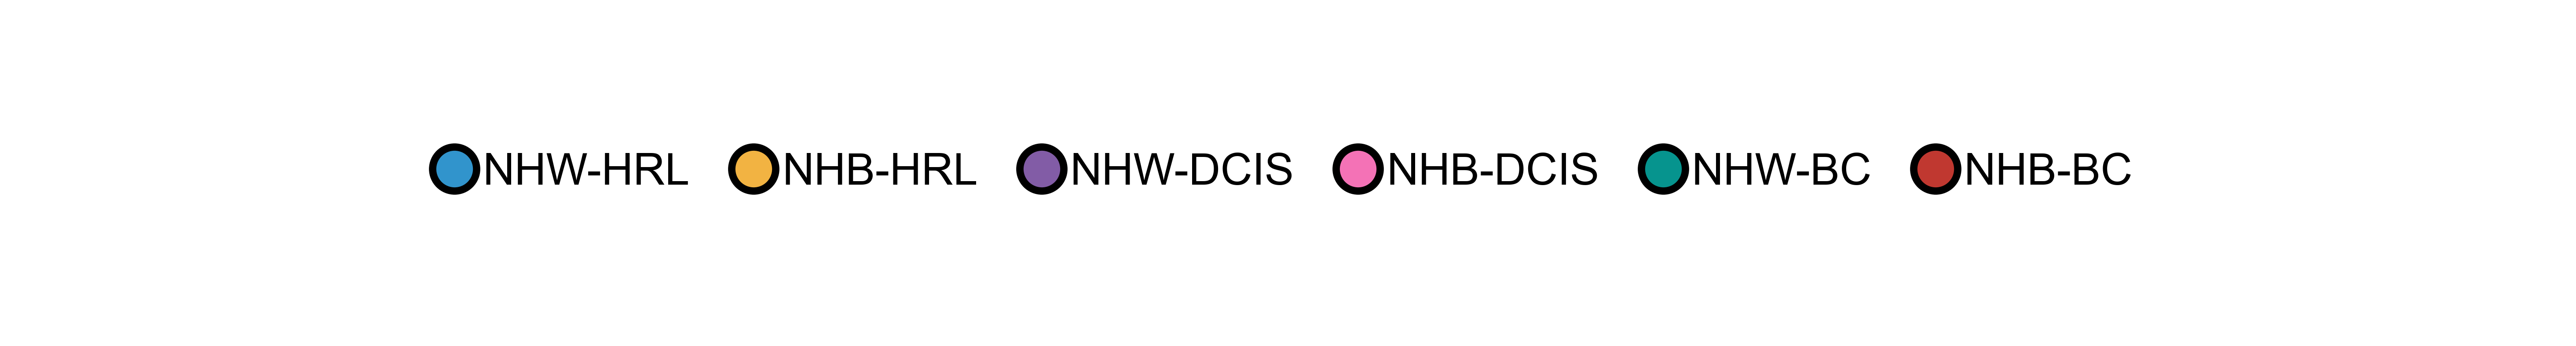

In [97]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# Define color mapping
color_set = {
    'NHW-HRL':'#3194CC',
    'NHB-HRL':'#F2B342',
    
    'NHW-DCIS':'#825CA6',
    'NHB-DCIS':'#F472B6',
    
    'NHW-BC':'#06948E',
    'NHB-BC':'#C03830'
}

# Order of legend items
legend_labels = list(color_set.keys())
legend_colors = [color_set[label] for label in legend_labels]

# Create circular marker legend handles
handles = [
    Line2D([0], [0], marker='o', color='none', markerfacecolor=color, markersize=6, label=label)
    for label, color in zip(legend_labels, legend_colors)
]

# Plot
fig, ax = plt.subplots(figsize=(6, 0.6))  # Adjust width as needed
ax.axis('off')

# Add legend
ax.legend(
    handles=handles,
    loc='center',
    frameon=False,
    ncol=len(handles),
    handletextpad=0.4,
    columnspacing=1.2,
    fontsize=6,
    borderaxespad=0.0
)

# Save
plt.savefig("plots/Legends/colorlegend_racestage_figS2.svg", bbox_inches='tight')
plt.show()

# By disease states
Pct of the main cell lineage

## Calc %

In [97]:
cells_ordered = [
    'Naive B','Mature B','Memory B','Plasmablast',
    'Naive CD4T','Central Memory CD4T','Effector Memory CD4T','Cytotoxic CD4T','Treg',
    'Naive CD8T','Central Memory CD8T','Effector Memory CD8T',
    'Double Negative T','γδ T','MAIT',
    'cDC1','cDC2','pDC',
    'Classical Monocyte','Intermediate Monocyte','Nonclassical Monocyte','Cytotoxic Monocyte',
    'CD56-dim NK','CD56-bright NK','Proliferating NK'
]


In [98]:
cells_group = {
    'B':[
 'Naive B',
 'Mature B',
 'Memory B',
 'Plasmablast'],
    
    'T':[
 'Naive CD4T',
 'Central Memory CD4T',
 'Effector Memory CD4T',
 'Cytotoxic CD4T',
 'Treg',
 'Naive CD8T',
 'Central Memory CD8T',
 'Effector Memory CD8T',
 'Double Negative T',
 'γδ T',
 'MAIT'],
    
    'DC':[
 'cDC1',
 'cDC2',
 'pDC'     
    ],
    
    'Mono':[
 'Classical Monocyte',
 'Intermediate Monocyte',
 'Nonclassical Monocyte',
 'Cytotoxic Monocyte'
        ],
    
    'NK':[
 'CD56-dim NK',
 'CD56-bright NK',
 'Proliferating NK'
    ]
}


In [99]:
new_pct = pd.DataFrame(index=pct.index, columns=pct.columns)

for group, cell_list in cells_group.items():
    # For each group, get the total per sample (across all group members)
    group_sum = pct.loc[cell_list].sum(axis=0)
    # Recalculate each member as a fraction of its group
    for cell in cell_list:
        new_pct.loc[cell] = pct.loc[cell] / group_sum

new_pct = new_pct.fillna(0) * 100
new_pct

,Pool137_14,Pool138_15,Pool138_14,Pool137_26,Pool138_9,Pool137_25,Pool137_29,Pool138_4,Pool137_10,Pool137_6,...,Pool138_19,Pool138_27,Pool137_31,Pool137_17,Pool137_16,Pool138_18,Pool138_29,Pool138_17,Pool138_20,Pool138_26
Naive B,58.190045,18.892900,60.820595,35.575827,50.688705,17.689906,57.598039,77.103867,59.555556,36.349693,...,24.644550,60.089286,78.250000,48.527282,40.848214,29.878049,74.837949,51.940299,48.226950,47.619048
Mature B,30.950226,58.122744,22.687047,51.197263,32.323232,65.972945,26.593137,11.144807,25.777778,36.042945,...,27.369668,19.553571,14.250000,37.566393,34.821429,45.731707,20.860342,25.671642,36.170213,35.714286
Memory B,9.683258,21.780987,12.791633,12.314709,16.528926,15.504683,13.480392,10.614102,12.000000,26.533742,...,35.781991,17.142857,6.875000,12.168035,21.316964,23.170732,4.301709,20.000000,11.702128,14.285714
Plasmablast,1.176471,1.203369,3.700724,0.912201,0.459137,0.832466,2.328431,1.137225,2.666667,1.073620,...,12.203791,3.214286,0.625000,1.738291,3.013393,1.219512,0.000000,2.388060,3.900709,2.380952
Naive CD4T,31.478294,31.011236,35.240546,31.237230,19.293326,27.913496,30.958502,33.834004,33.627137,19.508058,...,21.563444,14.222332,24.782284,16.353712,25.629723,34.707379,34.062165,17.335092,36.583042,19.495413
Central Memory CD4T,36.163702,30.458081,30.251435,35.550511,38.600673,43.932719,34.300404,40.693713,42.174145,31.580435,...,35.536254,54.794183,40.333416,48.253275,47.008816,37.251908,35.412647,47.229551,30.993966,47.293578
Cytotoxic CD4T,0.382482,0.414866,0.178183,0.385925,0.210320,0.841009,1.615865,0.340663,0.320513,0.310998,...,0.528701,0.147893,0.248818,0.305677,0.377834,0.814249,0.235798,0.659631,1.333757,0.229358
Effector Memory CD4T,4.934022,4.909248,4.850525,6.106697,7.501402,10.812976,3.562248,6.054506,4.326923,4.778061,...,6.570997,7.493222,4.951480,7.423581,3.967254,2.646310,3.558414,8.364116,3.112099,6.834862
Treg,4.245554,2.886776,2.712334,2.542565,2.706113,2.843412,1.799486,4.056984,2.297009,2.685892,...,2.945619,4.067045,2.786763,4.170306,4.691436,1.781170,4.244373,3.746702,5.430295,5.825688
Naive CD8T,12.736661,13.638721,13.759652,5.675369,2.327538,7.048458,16.048476,5.311242,6.917735,2.601074,...,20.128399,15.627311,21.000249,10.218341,8.028967,7.124682,2.915327,5.197889,1.683074,2.018349


In [100]:
pct_T = new_pct.T
pct_T.index.name = 'dataset_name'

pct_T_reset = pct_T.reset_index()
meta_reset = meta_ordered.reset_index()

dfp = pd.merge(pct_T_reset, meta_reset, on='dataset_name', how='inner')
dfp

,dataset_name,Naive B,Mature B,Memory B,Plasmablast,Naive CD4T,Central Memory CD4T,Cytotoxic CD4T,Effector Memory CD4T,Treg,...,Proliferating NK,sampleid,batch,viability_pct,group,race,age,diabetes,obesity,race-stage
0,Pool137_14,58.190045,30.950226,9.683258,1.176471,31.478294,36.163702,0.382482,4.934022,4.245554,...,1.208981,43-H,1,91,HRL,NHW,42.5,N,Y,NHW-HRL
1,Pool138_15,18.892900,58.122744,21.780987,1.203369,31.011236,30.458081,0.414866,4.909248,2.886776,...,1.391304,956-H,2,89,HRL,NHW,42.8,N,N,NHW-HRL
2,Pool138_14,60.820595,22.687047,12.791633,3.700724,35.240546,30.251435,0.178183,4.850525,2.712334,...,2.384501,568-H,2,93,HRL,NHW,43.7,N,N,NHW-HRL
3,Pool137_26,35.575827,51.197263,12.314709,0.912201,31.237230,35.550511,0.385925,6.106697,2.542565,...,0.750751,42-H,1,91,HRL,NHW,53.1,N,N,NHW-HRL
4,Pool138_9,50.688705,32.323232,16.528926,0.459137,19.293326,38.600673,0.210320,7.501402,2.706113,...,1.704545,63-H,2,98,HRL,NHW,57.7,N,Y,NHW-HRL
5,Pool137_25,17.689906,65.972945,15.504683,0.832466,27.913496,43.932719,0.841009,10.812976,2.843412,...,4.455446,36-H,1,90,HRL,NHW,59.6,N,N,NHW-HRL
6,Pool137_29,57.598039,26.593137,13.480392,2.328431,30.958502,34.300404,1.615865,3.562248,1.799486,...,1.966292,61-H,1,90,HRL,NHW,59.6,N,N,NHW-HRL
7,Pool138_4,77.103867,11.144807,10.614102,1.137225,33.834004,40.693713,0.340663,6.054506,4.056984,...,1.173403,24-H,2,94,HRL,NHW,60.5,N,Y,NHW-HRL
8,Pool137_10,59.555556,25.777778,12.000000,2.666667,33.627137,42.174145,0.320513,4.326923,2.297009,...,2.135922,1-H,1,88,HRL,NHW,62.3,N,N,NHW-HRL
9,Pool137_6,36.349693,36.042945,26.533742,1.073620,19.508058,31.580435,0.310998,4.778061,2.685892,...,2.189781,6-H,1,94,HRL,NHW,71.1,N,Y,NHW-HRL


In [59]:
dfp.to_csv('data/Figure2/ratio_majorCellTypes.csv')

## Calc FDR
Scanpro

In [37]:
# scanpro
level = 'celltype_level3'
var_cond = 'group'

idx = 0

for cell_major in ['B','T','DC','Mono','NK']:

    for race in ['NHW', 'NHB']:

        for pair in [['DCIS','HRL'], ['BC','HRL'], ['BC','DCIS']]:
        
            idx += 1
            
            sub = dat[
                (dat.obs['celltype_level3'].isin(cells_group[cell_major])) & 
                (dat.obs['race']==race) & 
                (dat.obs['group'].isin(pair))
                ]
            
            out = scanpro(sub, 
                  clusters_col=level, 
                  conds_col=var_cond, 
                  # covariates=[],
                  samples_col='sampleid')
    
            res = out.results
                 
            res['cell_major'] = cell_major
            tmp = '_'.join(pair)
            res['cf'] = race + '_' + tmp
            
    
            res_f = res if idx==1 else pd.concat((res_f, res))

res_f

NameError: name 'dat' is not defined

In [138]:
res_f

,baseline_props,mean_props_HRL,mean_props_DCIS,prop_ratio,t_statistics,p_values,adjusted_p_values,cell_major,cf,mean_props_BC
clusters,,,,,,,,,,
Naive B,0.490185,0.472465,0.532853,0.886670,-0.725177,0.476559,0.580503,B,NHW_DCIS_HRL,NaN
Mature B,0.354229,0.360812,0.316848,1.138753,0.570089,0.574827,0.580503,B,NHW_DCIS_HRL,NaN
Memory B,0.140772,0.151232,0.134762,1.122220,0.561582,0.580503,0.580503,B,NHW_DCIS_HRL,NaN
Plasmablast,0.014814,0.015490,0.015537,0.997024,0.584330,0.565388,0.580503,B,NHW_DCIS_HRL,NaN
Naive B,0.509495,0.472465,NaN,0.917824,-0.620260,0.539981,0.716748,B,NHW_BC_HRL,0.514767
...,...,...,...,...,...,...,...,...,...,...
CD56-bright NK,0.072229,0.073665,NaN,1.210804,0.610397,0.545282,0.663723,NK,NHB_BC_HRL,0.089194
Proliferating NK,0.015239,0.016167,NaN,1.216188,-1.156188,0.254919,0.663723,NK,NHB_BC_HRL,0.019662
CD56-dim NK,0.911639,NaN,0.915142,0.973777,-0.483197,0.635011,0.635011,NK,NHB_BC_DCIS,0.891144


In [139]:
res_f[res_f['adjusted_p_values']<.05]

,baseline_props,mean_props_HRL,mean_props_DCIS,prop_ratio,t_statistics,p_values,adjusted_p_values,cell_major,cf,mean_props_BC
clusters,,,,,,,,,,
γδ T,0.000969,0.001337,NaN,0.327109,-3.848779,0.000835,0.00919,T,NHB_BC_HRL,0.000437


In [140]:
res_f.to_csv('data/05_scanpro/by_diseasestate.csv')

## Export ST

In [62]:
res_f = pd.read_csv('data/05_scanpro/by_diseasestate.csv')
res_f

,clusters,baseline_props,mean_props_HRL,mean_props_DCIS,prop_ratio,t_statistics,p_values,adjusted_p_values,cell_major,cf,mean_props_BC
0,Naive B,0.490185,0.472465,0.532853,0.886670,-0.725177,0.476559,0.580503,B,NHW_DCIS_HRL,NaN
1,Mature B,0.354229,0.360812,0.316848,1.138753,0.570089,0.574827,0.580503,B,NHW_DCIS_HRL,NaN
2,Memory B,0.140772,0.151232,0.134762,1.122220,0.561582,0.580503,0.580503,B,NHW_DCIS_HRL,NaN
3,Plasmablast,0.014814,0.015490,0.015537,0.997024,0.584330,0.565388,0.580503,B,NHW_DCIS_HRL,NaN
4,Naive B,0.509495,0.472465,NaN,0.917824,-0.620260,0.539981,0.716748,B,NHW_BC_HRL,0.514767
...,...,...,...,...,...,...,...,...,...,...,...
145,CD56-bright NK,0.072229,0.073665,NaN,1.210804,0.610397,0.545282,0.663723,NK,NHB_BC_HRL,0.089194
146,Proliferating NK,0.015239,0.016167,NaN,1.216188,-1.156188,0.254919,0.663723,NK,NHB_BC_HRL,0.019662
147,CD56-dim NK,0.911639,NaN,0.915142,0.973777,-0.483197,0.635011,0.635011,NK,NHB_BC_DCIS,0.891144
148,CD56-bright NK,0.074195,NaN,0.068945,1.293687,0.574509,0.573016,0.635011,NK,NHB_BC_DCIS,0.089194


In [64]:
dft = res_f[[
     'clusters','cf',
    'mean_props_HRL', 'mean_props_DCIS', 'mean_props_BC',
        'p_values', 'adjusted_p_values'
]]
dft.columns = ['Cell type','Comparison group',
               'Mean proportion in HRL', 'Mean proportion in DCIS','Mean proportion in BC',
               'p-value', 'FDR-adjusted p-value'
              ]
dft

,Cell type,Comparison group,Mean proportion in HRL,Mean proportion in DCIS,Mean proportion in BC,p-value,FDR-adjusted p-value
0,Naive B,NHW_DCIS_HRL,0.472465,0.532853,NaN,0.476559,0.580503
1,Mature B,NHW_DCIS_HRL,0.360812,0.316848,NaN,0.574827,0.580503
2,Memory B,NHW_DCIS_HRL,0.151232,0.134762,NaN,0.580503,0.580503
3,Plasmablast,NHW_DCIS_HRL,0.015490,0.015537,NaN,0.565388,0.580503
4,Naive B,NHW_BC_HRL,0.472465,NaN,0.514767,0.539981,0.716748
...,...,...,...,...,...,...,...
145,CD56-bright NK,NHB_BC_HRL,0.073665,NaN,0.089194,0.545282,0.663723
146,Proliferating NK,NHB_BC_HRL,0.016167,NaN,0.019662,0.254919,0.663723
147,CD56-dim NK,NHB_BC_DCIS,NaN,0.915142,0.891144,0.635011,0.635011
148,CD56-bright NK,NHB_BC_DCIS,NaN,0.068945,0.089194,0.573016,0.635011


In [65]:
dft.to_csv('data/Tables/!ST_propByDzState.csv', index=False)

## Plot

In [53]:
ratio = pd.read_csv('data/Figure2/ratio_majorCellTypes.csv', index_col=0)
ratio

,dataset_name,Naive B,Mature B,Memory B,Plasmablast,Naive CD4T,Central Memory CD4T,Effector Memory CD4T,Cytotoxic CD4T,Treg,...,CD56-bright NK,Proliferating NK,batch,viability_pct,group,race,age,diabetes,obesity,race-stage
0,Pool137_14,58.190045,30.950226,9.683258,1.176471,31.478294,36.163702,4.934022,0.382482,4.245554,...,7.512953,1.208981,1,91,HRL,NHW,42.5,N,Y,NHW-HRL
1,Pool138_15,18.892900,58.122744,21.780987,1.203369,31.011236,30.458081,4.909248,0.414866,2.886776,...,15.130435,1.391304,2,89,HRL,NHW,42.8,N,N,NHW-HRL
2,Pool138_14,60.820595,22.687047,12.791633,3.700724,35.240546,30.251435,4.850525,0.178183,2.712334,...,9.687034,2.384501,2,93,HRL,NHW,43.7,N,N,NHW-HRL
3,Pool137_26,35.575827,51.197263,12.314709,0.912201,31.237230,35.550511,6.106697,0.385925,2.542565,...,11.111111,0.750751,1,91,HRL,NHW,53.1,N,N,NHW-HRL
4,Pool138_9,50.688705,32.323232,16.528926,0.459137,19.293326,38.600673,7.501402,0.210320,2.706113,...,4.545455,1.704545,2,98,HRL,NHW,57.7,N,Y,NHW-HRL
5,Pool137_25,17.689906,65.972945,15.504683,0.832466,27.913496,43.932719,10.812976,0.841009,2.843412,...,14.356436,4.455446,1,90,HRL,NHW,59.6,N,N,NHW-HRL
6,Pool137_29,57.598039,26.593137,13.480392,2.328431,30.958502,34.300404,3.562248,1.615865,1.799486,...,7.022472,1.966292,1,90,HRL,NHW,59.6,N,N,NHW-HRL
7,Pool138_4,77.103867,11.144807,10.614102,1.137225,33.834004,40.693713,6.054506,0.340663,4.056984,...,10.821382,1.173403,2,94,HRL,NHW,60.5,N,Y,NHW-HRL
8,Pool137_10,59.555556,25.777778,12.000000,2.666667,33.627137,42.174145,4.326923,0.320513,2.297009,...,4.077670,2.135922,1,88,HRL,NHW,62.3,N,N,NHW-HRL
9,Pool137_6,36.349693,36.042945,26.533742,1.073620,19.508058,31.580435,4.778061,0.310998,2.685892,...,6.934307,2.189781,1,94,HRL,NHW,71.1,N,Y,NHW-HRL


In [54]:
# prep
from statannotations.Annotator import Annotator
from scipy.stats import f_oneway

dfp = ratio.copy()

dfp['race-stage'] = pd.Categorical(
    dfp['race-stage'],
    categories=['NHW-HRL','NHW-DCIS','NHW-BC', 
                'NHB-HRL','NHB-DCIS','NHB-BC'],
    ordered=True
    )

color_set = {
    'NHW-HRL':'#3194CC',
    'NHW-DCIS':'#825CA6',
    'NHW-BC':'#06948E',
    
    'NHB-HRL':'#F2B342',
    'NHB-DCIS':'#F472B6',
    'NHB-BC':'#C03830',

    'Diabetes':'navy',
    'Obesity':'salmon'

}


cells_group = {
    'B':['Naive B',
 'Mature B',
 'Memory B',
 'Plasmablast'],
    'T':['Naive CD4T',
 'Central Memory CD4T',
 'Effector Memory CD4T',
 'Cytotoxic CD4T',
 'Treg',
 'Naive CD8T',
 'Central Memory CD8T',
 'Effector Memory CD8T',
 'Double Negative T',
 'γδ T',
 'MAIT'],
    'DC':[
   'cDC1',
 'cDC2',
 'pDC'     
    ],
    'Mono':[
        'Classical Monocyte',
 'Intermediate Monocyte',
 'Nonclassical Monocyte',
 'Cytotoxic Monocyte'
        ],
    'NK':[
        'CD56-dim NK',
 'CD56-bright NK',
 'Proliferating NK'
    ]
}



# Define the group for each pair (extract the trailing substring after '-' from NHW-HRL, etc.)
def get_race(pair):
    # E.g., ('NHB-HRL', 'NHB-DCIS') -> 'NHB'
    return pair[0].split('-')[0]

def get_comparison(pair):
    # E.g., ('NHB-DCIS', 'NHB-HRL') -> 'DCIS vs HRL'
    a = pair[0].split('-')[1]
    b = pair[1].split('-')[1]
    return f'{a} vs {b}'


def pval_to_star(p):
    # Customize as you wish (this is standard)
    if p < 0.001:
        return '***'
    elif p < 0.01:
        return '**'
    elif p < 0.05:
        return '*'
    else:
        return 'ns'

def get_group_from_celltype(celltype, cells_group):
    for group, members in cells_group.items():
        if celltype == members or celltype in members:
            return group
    return None



In [55]:
res_f = pd.read_csv('data/05_scanpro/by_diseasestate.csv', index_col=0)
res_f

,baseline_props,mean_props_HRL,mean_props_DCIS,prop_ratio,t_statistics,p_values,adjusted_p_values,cell_major,cf,mean_props_BC
clusters,,,,,,,,,,
Naive B,0.490185,0.472465,0.532853,0.886670,-0.725177,0.476559,0.580503,B,NHW_DCIS_HRL,NaN
Mature B,0.354229,0.360812,0.316848,1.138753,0.570089,0.574827,0.580503,B,NHW_DCIS_HRL,NaN
Memory B,0.140772,0.151232,0.134762,1.122220,0.561582,0.580503,0.580503,B,NHW_DCIS_HRL,NaN
Plasmablast,0.014814,0.015490,0.015537,0.997024,0.584330,0.565388,0.580503,B,NHW_DCIS_HRL,NaN
Naive B,0.509495,0.472465,NaN,0.917824,-0.620260,0.539981,0.716748,B,NHW_BC_HRL,0.514767
...,...,...,...,...,...,...,...,...,...,...
CD56-bright NK,0.072229,0.073665,NaN,1.210804,0.610397,0.545282,0.663723,NK,NHB_BC_HRL,0.089194
Proliferating NK,0.015239,0.016167,NaN,1.216188,-1.156188,0.254919,0.663723,NK,NHB_BC_HRL,0.019662
CD56-dim NK,0.911639,NaN,0.915142,0.973777,-0.483197,0.635011,0.635011,NK,NHB_BC_DCIS,0.891144


In [58]:
res_f[res_f['adjusted_p_values']<.05]

,baseline_props,mean_props_HRL,mean_props_DCIS,prop_ratio,t_statistics,p_values,adjusted_p_values,cell_major,cf,mean_props_BC
clusters,,,,,,,,,,
γδ T,0.000969,0.001337,NaN,0.327109,-3.848779,0.000835,0.00919,T,NHB_BC_HRL,0.000437


In [59]:
Counter(res_f['cf'])

Counter({'NHW_DCIS_HRL': 25,
         'NHW_BC_HRL': 25,
         'NHW_BC_DCIS': 25,
         'NHB_DCIS_HRL': 25,
         'NHB_BC_HRL': 25,
         'NHB_BC_DCIS': 25})

In [60]:
# significant

cells_plot = [x for x in cells_ordered if x in res_f[res_f['adjusted_p_values']<.1].index.unique()]
cells_plot

['γδ T']

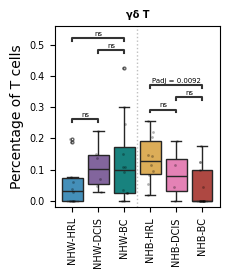

In [61]:
# plot significant one
ncol = 1
features = cells_plot  # the cell type names
nrow = int(np.ceil(len(features)/ncol))
figwidth = 2.5
figheight = 3    # or adjust as needed

fig, axs = plt.subplots(nrow, ncol, figsize=(figwidth, figheight), sharex=True)
# fig.subplots_adjust(wspace=0.4)

# axs = axs.flatten()

for i, yname in enumerate(features):
    ax = axs
    sns.boxplot(
        data=dfp,
        x='race-stage',
        y=yname,
        hue='race-stage',
        palette=color_set,
        flierprops=dict(marker='o', markersize=2, alpha=0.7),
        ax=ax,
        showfliers=True
    )
    sns.stripplot(
        data=dfp, x='race-stage', y=yname, size=2, color='black', alpha=.3, ax=ax
    )
    
    n_cat = dfp['race-stage'].nunique()
    split_x = n_cat / 2 - 0.5   # 6 → 2.5
    
    ax.axvline(
        x=split_x,
        linestyle=':',
        color='gray',
        alpha=0.5,
        linewidth=1
    )

    
    pairs = [
        ('NHW-DCIS', 'NHW-HRL'),('NHW-BC', 'NHW-DCIS'),('NHW-BC', 'NHW-HRL'),
        ('NHB-DCIS', 'NHB-HRL'),('NHB-BC', 'NHB-DCIS'),('NHB-BC', 'NHB-HRL')
    ]
    
    # --- Prepare custom pvalues (and stars) ---
    custom_annotations = []
    
    for pair in pairs:
        
        str1 = pair[0].split('-')[0]
        str2 = pair[0].split('-')[1]
        str3 = pair[1].split('-')[1]
        cf = f'{str1}_{str2}_{str3}'
    
        try:
            padj = (
                res_f.loc[yname]
                .query("cf == @cf")["adjusted_p_values"]   # your adjusted p-values
                .iloc[0]
            )
            padj = float(padj)
    
            if padj > 0.05:
                label = "ns"
            else:
                label = f"Padj = {padj:.2g}"
    
    
        except Exception as e:
            print(f"Missing adjusted p-value for {yname}, {group}: {e}")
            label = "Padj = NA"
    
        custom_annotations.append(label)
    
    
    annotator = Annotator(
        ax,
        pairs,
        data=dfp,
        x="race-stage",
        y=yname,
    )
    
    annotator.configure(
        loc="inside",
        verbose=False,
        fontsize=5
    )

    annotator.set_custom_annotations(custom_annotations)
    annotator.annotate()


    groupname = get_group_from_celltype(yname, cells_group)


    ax.set_title(yname, fontsize=7, color='k', fontweight='bold')
    ax.set_xlabel('')
    ax.set_ylabel(f'Percentage of {groupname} cells')  # Hide to save space
    ax.tick_params(axis='x', labelsize=7, rotation=90)
    ax.tick_params(axis='y', labelsize=7)
    ax.legend([],[], frameon=False)  # Remove legend

    # for tick_label in ax.get_xticklabels():
    #     group = tick_label.get_text()
    #     if group in color_set:
    #         tick_label.set_color(color_set[group])

# Hide any unused subplots
# for j in range(i+1, len(axs)):
#     axs[j].set_visible(False)


group_palette = {
    'NHW': '#95AAD3',   # blue
    'NHB': '#E07F80'  # pink
}

# Mapping from tick positions (0-based index) to group labels
tick_groups = {
    (0, 2): 'NHW',
    (3, 5): 'NHB'
}
        

# Shared axis label
fig.text(0.5, 0.04, '', ha='center', fontsize=7)
# fig.text(0.03, 0.5, 'Percentage of', va='center', rotation='vertical', fontsize=7)


plt.tight_layout(rect=[0.04, 0.04, 1, 1])  # leave space for axis labels
plt.savefig('plots/F2/RE_byDzState.svg', bbox_inches='tight', dpi=600)

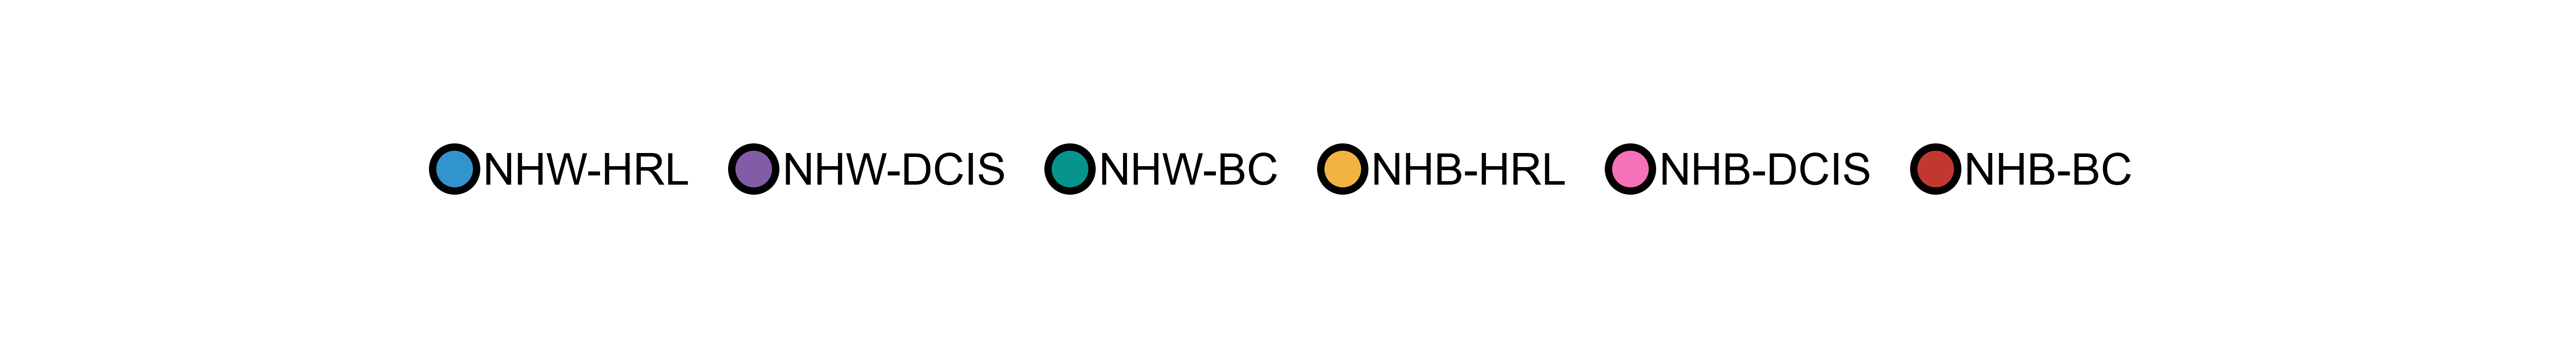

In [66]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# Define color mapping
color_set = {
    'NHW-HRL':'#3194CC',
    'NHW-DCIS':'#825CA6',
    'NHW-BC':'#06948E',
    
    'NHB-HRL':'#F2B342',
    'NHB-DCIS':'#F472B6',
    'NHB-BC':'#C03830'
}

# Order of legend items
legend_labels = list(color_set.keys())
legend_colors = [color_set[label] for label in legend_labels]

# Create circular marker legend handles
handles = [
    Line2D([0], [0], marker='o', color='none', markerfacecolor=color, markersize=6, label=label)
    for label, color in zip(legend_labels, legend_colors)
]

# Plot
fig, ax = plt.subplots(figsize=(6, 0.6))  # Adjust width as needed
ax.axis('off')

# Add legend
ax.legend(
    handles=handles,
    loc='center',
    frameon=False,
    ncol=len(handles),
    handletextpad=0.4,
    columnspacing=1.2,
    fontsize=6,
    borderaxespad=0.0
)

# Save
plt.savefig("plots/Legends/colorlegend_stagerace.svg", bbox_inches='tight')
plt.show()

# Save plot settings

In [27]:
plt_race_stage = {
    'NHW-HRL':'#DDF1F5',
    'NHW-DCIS':'#BAB4D8',
    'NHW-BC':'#06948E',
    
    'NHB-HRL':'#F4E6AA',
    'NHB-DCIS':'#A28070',
    'NHB-BC':'#C03830',
    
    'Diabetes':'#F472B6',
    'Obesity':'#F59E42'

}

plt_major_celltype = {
    'B':    '#3072C4',   # strong blue
    'T':    '#EF763F',   # bold orange
    'DC':   '#35A293',   # teal
    'Mono': '#B3813E',   # rich brown/gold
    'NK':   '#7D4C99'   # deep purple
}

cells_group = {
    'B':['Naive B',
 'Mature B',
 'Memory B',
 'Plasmablast'],
    'T':['Naive CD4T',
 'Central Memory CD4T',
 'Effector Memory CD4T',
 'Cytotoxic CD4T',
 'Treg',
 'Naive CD8T',
 'Central Memory CD8T',
 'Effector Memory CD8T',
 'Double Negative T',
 'γδ T',
 'MAIT'],
    'DC':[
   'cDC1',
 'cDC2',
 'pDC'     
    ],
    'Mono':[
        'Classical Monocyte',
 'Intermediate Monocyte',
 'Nonclassical Monocyte',
 'Cytotoxic Monocyte'
        ],
    'NK':[
        'CD56-dim NK',
 'CD56-bright NK',
 'Proliferating NK'
    ]
}

import seaborn as sns
import random

n = 25
colors = sns.color_palette('tab20', 20) + sns.color_palette('Set3', 5)

random.seed(1024)
random.shuffle(colors)  # simple option, or design a custom reordering

plt_celltype = dict(zip(cells_ordered, colors))

In [28]:
plt_data = {
    'plt_race_stage':plt_race_stage,
    'plt_major_celltype':plt_major_celltype,
    'cells_group':cells_group,
    'plt_celltype':plt_celltype
}

with open('data/Legends/palette.pkl','wb') as f:
    pkl.dump(plt_data,f)


# Scanpro for major cell type composition

## By race

In [23]:
pct = pd.read_csv('data/Figure2/majorCellType_pct.csv',
                  index_col=0
                 )
pct

,Pool137_6,Pool137_7,Pool137_8,Pool137_9,Pool137_10,Pool137_11,Pool137_12,Pool137_14,Pool137_15,Pool137_16,...,Pool138_19,Pool138_20,Pool138_21,Pool138_22,Pool138_23,Pool138_24,Pool138_25,Pool138_26,Pool138_27,Pool138_29
B,9.794202,15.872012,23.404527,12.026002,3.039308,4.916898,5.531258,12.055422,14.090431,14.299394,...,15.334302,4.325153,9.849040,11.694332,7.440236,13.162508,10.269533,6.589269,12.698413,22.390817
CD4 T,31.275349,33.969900,49.341348,51.648352,41.847900,43.732687,16.979676,44.043203,35.015773,41.398021,...,32.303779,37.407975,38.267624,35.681172,23.207091,27.673635,30.791539,27.251334,37.131519,47.710780
CD8 T,14.300736,15.682307,6.356312,5.943352,7.740105,18.732687,16.413687,10.560768,18.927445,8.027450,...,15.461483,10.889571,20.093800,18.857485,11.925866,27.120701,14.790174,6.369627,7.845805,13.788099
DC,1.667418,1.416466,1.138253,1.238198,2.688099,2.158356,2.778492,1.745581,1.892744,1.915097,...,2.670785,1.978528,2.594167,1.420667,4.217029,1.402562,1.774139,1.459052,1.575964,1.622905
Mono,27.174403,18.388769,14.439187,18.062219,29.785222,23.337950,47.671726,16.517565,22.712934,26.859240,...,29.087936,28.067485,20.342958,13.817856,46.360462,15.455158,38.348686,42.218387,22.913832,8.008972
NK,8.231936,9.649678,4.872746,10.818759,13.913278,5.170822,9.724723,12.633646,4.942166,6.240026,...,4.796512,17.331288,5.481460,13.668312,5.613752,9.723533,3.394746,15.531848,16.814059,6.425650
other T,7.555956,5.020868,0.447628,0.263117,0.986087,1.950600,0.900437,2.443814,2.418507,1.260772,...,0.345203,0.000000,3.370951,4.860176,1.235563,5.461902,0.631184,0.580483,1.020408,0.052777


In [28]:
Counter(dat.obs['predicted.celltype.l1'])

Counter({'CD4 T': 167053,
         'Mono': 108864,
         'CD8 T': 56297,
         'B': 49158,
         'NK': 36671,
         'other T': 8586,
         'DC': 7936})

In [30]:
# scanpro
level = 'predicted.celltype.l1'
var_cond = 'race'

idx = 0
for group in ['HRL','DCIS','BC']:

    idx += 1

    sub = dat[(dat.obs['group']==group)]
    
    out = scanpro(sub, 
          clusters_col=level, 
          conds_col=var_cond, 
          # covariates=vars_adj,
          samples_col='sampleid')

    res = out.results
    
    res['group'] = group
    

    res_f = res if idx==1 else pd.concat((res_f, res))

res_f

[INFO] There are 2 conditions. T-Test will be performed...
[INFO] Done!
[INFO] There are 2 conditions. T-Test will be performed...
[INFO] Done!
[INFO] There are 2 conditions. T-Test will be performed...
[INFO] Done!


,baseline_props,mean_props_NHW,mean_props_NHB,prop_ratio,t_statistics,p_values,adjusted_p_values,group
clusters,,,,,,,,
B,0.107246,0.103309,0.112609,0.917417,-0.657247,0.518539,0.586508,HRL
CD4 T,0.398418,0.384848,0.407638,0.944091,-0.678319,0.505368,0.586508,HRL
CD8 T,0.130166,0.110620,0.143536,0.770676,-0.735395,0.470664,0.586508,HRL
DC,0.019285,0.023521,0.016195,1.452363,1.971401,0.062719,0.325326,HRL
Mono,0.246529,0.283377,0.217939,1.300255,1.764593,0.092950,0.325326,HRL
NK,0.077954,0.074009,0.082350,0.898715,-0.718050,0.481058,0.586508,HRL
other T,0.020401,0.020316,0.019732,1.029587,-0.552857,0.586508,0.586508,HRL
B,0.113055,0.099127,0.164224,0.603605,-1.016928,0.320947,0.584626,DCIS
CD4 T,0.382787,0.354607,0.408477,0.868120,-0.684755,0.501108,0.584626,DCIS


In [32]:
res_f.to_csv('data/05_scanpro/MajorCellType_byrace.csv')

### Export ST

In [66]:
res_f = pd.read_csv('data/05_scanpro/MajorCellType_byrace.csv')
res_f

,clusters,baseline_props,mean_props_NHW,mean_props_NHB,prop_ratio,t_statistics,p_values,adjusted_p_values,group
0,B,0.107246,0.103309,0.112609,0.917417,-0.657247,0.518539,0.586508,HRL
1,CD4 T,0.398418,0.384848,0.407638,0.944091,-0.678319,0.505368,0.586508,HRL
2,CD8 T,0.130166,0.110620,0.143536,0.770676,-0.735395,0.470664,0.586508,HRL
3,DC,0.019285,0.023521,0.016195,1.452363,1.971401,0.062719,0.325326,HRL
4,Mono,0.246529,0.283377,0.217939,1.300255,1.764593,0.092950,0.325326,HRL
5,NK,0.077954,0.074009,0.082350,0.898715,-0.718050,0.481058,0.586508,HRL
6,other T,0.020401,0.020316,0.019732,1.029587,-0.552857,0.586508,0.586508,HRL
7,B,0.113055,0.099127,0.164224,0.603605,-1.016928,0.320947,0.584626,DCIS
8,CD4 T,0.382787,0.354607,0.408477,0.868120,-0.684755,0.501108,0.584626,DCIS
9,CD8 T,0.136890,0.143027,0.111590,1.281710,0.869690,0.394460,0.584626,DCIS


In [67]:
dft = res_f[[
     'clusters','group',
    'mean_props_NHW', 'mean_props_NHB', 'prop_ratio',
        'p_values', 'adjusted_p_values'
]]
dft.columns = ['Cell type','Disease state',
               'Mean proportion in NHW', 'Mean proportion in NHB',
               'Proportion ratio NHW/NHB',
               'p-value', 'FDR-adjusted p-value'
              ]
dft

,Cell type,Disease state,Mean proportion in NHW,Mean proportion in NHB,Proportion ratio NHW/NHB,p-value,FDR-adjusted p-value
0,B,HRL,0.103309,0.112609,0.917417,0.518539,0.586508
1,CD4 T,HRL,0.384848,0.407638,0.944091,0.505368,0.586508
2,CD8 T,HRL,0.110620,0.143536,0.770676,0.470664,0.586508
3,DC,HRL,0.023521,0.016195,1.452363,0.062719,0.325326
4,Mono,HRL,0.283377,0.217939,1.300255,0.092950,0.325326
5,NK,HRL,0.074009,0.082350,0.898715,0.481058,0.586508
6,other T,HRL,0.020316,0.019732,1.029587,0.586508,0.586508
7,B,DCIS,0.099127,0.164224,0.603605,0.320947,0.584626
8,CD4 T,DCIS,0.354607,0.408477,0.868120,0.501108,0.584626
9,CD8 T,DCIS,0.143027,0.111590,1.281710,0.394460,0.584626


In [68]:
dft.to_csv('data/Tables/!ST_propByraceMajorcelltype.csv', index=False)

## By DzState

In [34]:
# scanpro
level = 'predicted.celltype.l1'
var_cond = 'group'

idx = 0

for race in ['NHW', 'NHB']:

    for pair in [['DCIS','HRL'], ['BC','HRL'], ['BC','DCIS']]:
    
        idx += 1
        
        sub = dat[
            (dat.obs['race']==race) & 
            (dat.obs['group'].isin(pair))
            ]
        
        out = scanpro(sub, 
              clusters_col=level, 
              conds_col=var_cond, 
              # covariates=[],
              samples_col='sampleid')

        res = out.results
             
        tmp = '_'.join(pair)
        res['cf'] = race + '_' + tmp
        

        res_f = res if idx==1 else pd.concat((res_f, res))

res_f

[INFO] There are 2 conditions. T-Test will be performed...
[INFO] Done!
[INFO] There are 2 conditions. T-Test will be performed...
[INFO] Done!
[INFO] There are 2 conditions. T-Test will be performed...
[INFO] Done!
[INFO] There are 2 conditions. T-Test will be performed...
[INFO] Done!
[INFO] There are 2 conditions. T-Test will be performed...
[INFO] Done!
[INFO] There are 2 conditions. T-Test will be performed...
[INFO] Done!


,baseline_props,mean_props_HRL,mean_props_DCIS,prop_ratio,t_statistics,p_values,adjusted_p_values,cf,mean_props_BC
clusters,,,,,,,,,
B,0.102479,0.103309,0.099127,1.042196,0.125892,0.901375,0.901375,NHW_DCIS_HRL,NaN
CD4 T,0.387997,0.384848,0.354607,1.085279,0.716937,0.483678,0.753746,NHW_DCIS_HRL,NaN
CD8 T,0.123315,0.110620,0.143027,0.773421,-1.294960,0.213585,0.640311,NHW_DCIS_HRL,NaN
DC,0.020521,0.023521,0.017810,1.320648,1.231084,0.235961,0.640311,NHW_DCIS_HRL,NaN
Mono,0.262102,0.283377,0.264061,1.073150,0.467978,0.646068,0.753746,NHW_DCIS_HRL,NaN
NK,0.078750,0.074009,0.086984,0.850840,-0.499511,0.624172,0.753746,NHW_DCIS_HRL,NaN
other T,0.024836,0.020316,0.034385,0.590841,-1.131469,0.274419,0.640311,NHW_DCIS_HRL,NaN
B,0.104714,0.103309,NaN,0.920430,-0.257454,0.799207,0.932408,NHW_BC_HRL,0.112240
CD4 T,0.383094,0.384848,NaN,1.036688,0.389866,0.700363,0.932408,NHW_BC_HRL,0.371228


In [35]:
res_f.to_csv('data/05_scanpro/MajorCellType_byDzState.csv')

### Export ST

In [69]:
res_f = pd.read_csv('data/05_scanpro/MajorCellType_byDzState.csv')
res_f

,clusters,baseline_props,mean_props_HRL,mean_props_DCIS,prop_ratio,t_statistics,p_values,adjusted_p_values,cf,mean_props_BC
0,B,0.102479,0.103309,0.099127,1.042196,0.125892,0.901375,0.901375,NHW_DCIS_HRL,NaN
1,CD4 T,0.387997,0.384848,0.354607,1.085279,0.716937,0.483678,0.753746,NHW_DCIS_HRL,NaN
2,CD8 T,0.123315,0.110620,0.143027,0.773421,-1.294960,0.213585,0.640311,NHW_DCIS_HRL,NaN
3,DC,0.020521,0.023521,0.017810,1.320648,1.231084,0.235961,0.640311,NHW_DCIS_HRL,NaN
4,Mono,0.262102,0.283377,0.264061,1.073150,0.467978,0.646068,0.753746,NHW_DCIS_HRL,NaN
5,NK,0.078750,0.074009,0.086984,0.850840,-0.499511,0.624172,0.753746,NHW_DCIS_HRL,NaN
6,other T,0.024836,0.020316,0.034385,0.590841,-1.131469,0.274419,0.640311,NHW_DCIS_HRL,NaN
7,B,0.104714,0.103309,NaN,0.920430,-0.257454,0.799207,0.932408,NHW_BC_HRL,0.112240
8,CD4 T,0.383094,0.384848,NaN,1.036688,0.389866,0.700363,0.932408,NHW_BC_HRL,0.371228
9,CD8 T,0.125251,0.110620,NaN,0.819259,-0.380418,0.707262,0.932408,NHW_BC_HRL,0.135024


In [70]:
dft = res_f[[
     'clusters','cf',
    'mean_props_HRL', 'mean_props_DCIS', 'mean_props_BC',
        'p_values', 'adjusted_p_values'
]]
dft.columns = ['Cell type','Comparison group',
               'Mean proportion in HRL', 'Mean proportion in DCIS','Mean proportion in BC',
               'p-value', 'FDR-adjusted p-value'
              ]
dft

,Cell type,Comparison group,Mean proportion in HRL,Mean proportion in DCIS,Mean proportion in BC,p-value,FDR-adjusted p-value
0,B,NHW_DCIS_HRL,0.103309,0.099127,NaN,0.901375,0.901375
1,CD4 T,NHW_DCIS_HRL,0.384848,0.354607,NaN,0.483678,0.753746
2,CD8 T,NHW_DCIS_HRL,0.110620,0.143027,NaN,0.213585,0.640311
3,DC,NHW_DCIS_HRL,0.023521,0.017810,NaN,0.235961,0.640311
4,Mono,NHW_DCIS_HRL,0.283377,0.264061,NaN,0.646068,0.753746
5,NK,NHW_DCIS_HRL,0.074009,0.086984,NaN,0.624172,0.753746
6,other T,NHW_DCIS_HRL,0.020316,0.034385,NaN,0.274419,0.640311
7,B,NHW_BC_HRL,0.103309,NaN,0.112240,0.799207,0.932408
8,CD4 T,NHW_BC_HRL,0.384848,NaN,0.371228,0.700363,0.932408
9,CD8 T,NHW_BC_HRL,0.110620,NaN,0.135024,0.707262,0.932408


In [71]:
dft.to_csv('data/Tables/!ST_propByDzStateMajorCellType.csv', index=False)